## Чекпойнт 2 EDA
## Датасет: Online Shoppers Purchasing Intention Dataset из UCI. ##
## Описание данных

* `Administrative` - Сколько административных страниц (аккаунт, профиль) посетил пользователь за сессию
* `Administrative_Duration` - Время, проведённое на административных страницах (в секундах)
* `Informational` - Сколько информационных страниц (о компании, контакты, доставка) посетил пользователь
* `Informational_Duration` - Время, проведённое на информационных страницах (в секундах)
* `ProductRelated` - Сколько страниц с товарами посетил пользователь
* `ProductRelated_Duration` - Время, проведённое на страницах с товарами (в секундах)
* `BounceRates` - Средняя доля посетителей, которые зашли на страницу и ушли, не совершив больше никаких действий (от 0 до 1)
* `ExitRates` - Средняя доля просмотров страницы, после которых сессия закончилась (от 0 до 1)
* `PageValues` - Средняя «ценность» страницы: насколько её посещение связано с последующей покупкой
* `SpecialDay` - Близость даты визита к особому дню, например к празднику (от 0 до 1, чем ближе к празднику, тем больше)
* `Month` - Месяц, в котором проходила сессия
* `OperatingSystems` - Код операционной системы пользователя (от 1 до 8)
* `Browser` - Код браузера пользователя (от 1 до 13)
* `Region` - Код региона пользователя (от 1 до 9)
* `TrafficType` - Код источника трафика, например реклама, поиск или прямой заход (от 1 до 20)
* `VisitorType` - Тип посетителя (Returning_Visitor, New_Visitor, Other)
* `Weekend` - Был ли визит в выходной день (True, False)
* `Revenue` - Закончилась ли сессия покупкой (True, False)

Загрузим данные

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
url = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
df = pd.read_csv(url, compression="zip")

## Исследование данных

Узнаем сколько сессий и признаков.
Получается 12330 сессий и 18 признаков.

In [2]:
df.shape

(12330, 18)

Узнаем тип данных в столбцах

In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

Узнаем есть ли пропуски в таблице.

Получается их нет.

In [4]:
df.isna().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [5]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist() # числовые колоноки
zeros = (df[num_cols] == 0).mean().mul(100).round(1).sort_values(ascending=False)
print(zeros)

SpecialDay                 89.9
Informational_Duration     80.5
Informational              78.7
PageValues                 77.9
Administrative_Duration    47.9
Administrative             46.8
BounceRates                44.8
ProductRelated_Duration     6.1
ExitRates                   0.6
ProductRelated              0.3
OperatingSystems            0.0
Browser                     0.0
Region                      0.0
TrafficType                 0.0
dtype: float64


Пропущенных значений в данных нет (все 18 столбцов заполнены полностью), но датасет сильно разрежен в смысле нулей. Эти нули содержательны посетитель не заходил в соответствующий раздел или сессия не имела ценности для конверсии, поэтому мы не считаем их пропусками и не заполняем.

Проверим есть ли дубликаты

In [6]:
df.duplicated().sum()

np.int64(125)

In [7]:
# Смотрим на сами дубликаты
dupes = df[df.duplicated(keep=False)]
print(f"Всего строк в дублях: {len(dupes)}")
print(f"Уникальных групп дублей: {len(dupes) - df.duplicated().sum()}")
print("\nПримеры:")
print(dupes.head(10))

# Есть ли среди дублей покупки?
print("\nРаспределение Revenue среди дубликатов:")
print(dupes['Revenue'].value_counts())

Всего строк в дублях: 201
Уникальных групп дублей: 76

Примеры:
     Administrative  Administrative_Duration  Informational  \
85                0                      0.0              0   
132               0                      0.0              0   
158               0                      0.0              0   
159               0                      0.0              0   
178               0                      0.0              0   
252               0                      0.0              0   
286               0                      0.0              0   
293               0                      0.0              0   
298               0                      0.0              0   
330               0                      0.0              0   

     Informational_Duration  ProductRelated  ProductRelated_Duration  \
85                      0.0               1                      0.0   
132                     0.0               1                      0.0   
158                     0.

Найдено 201 строка, входящих в 76 групп дублей. То есть 125 строк  это лишние копии, которые нужно удалить.

Все 201 строка имеют Revenue = False - среди дубликатов нет ни одной покупки. Удаление не затронет ни одного покупателя. Риск переобучения понижается.

Удалим дубликаты.

In [14]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(12205, 18)

In [10]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [15]:
df.describe(include='all')

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205,12205.000000,12205.000000,12205.000000,12205.000000,12205,12205,12205
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3329,NaN,NaN,NaN,NaN,10431,9346,10297
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,NaN,2.124211,2.357804,3.153298,4.073904,NaN,NaN,NaN
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,NaN,0.906823,1.710114,2.402340,4.016654,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


Целевая переменная покупок 15,63%.
Несбалансировано.

In [16]:
df['Revenue'].value_counts(normalize=True).mul(100).round(2)

,proportion
Revenue,
False,84.37
True,15.63


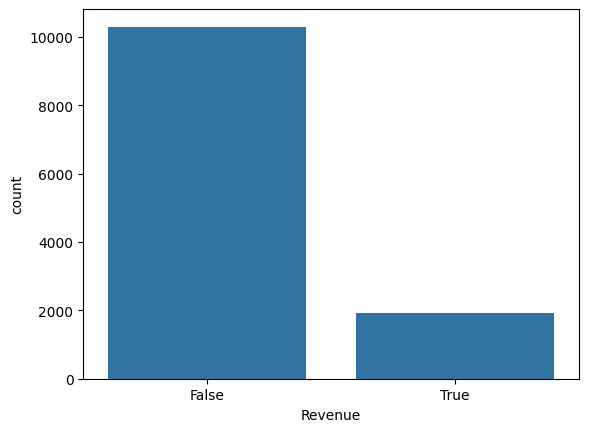

In [17]:
df.Revenue.value_counts()
df.Revenue.value_counts(normalize=True)   # то же в долях
sns.countplot(x='Revenue', data=df)
plt.show()

##Проверим есть ли ошибки в данных

In [18]:
# 1. Нет ли отрицательных значений
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist() # числовые колоноки
(df[num_cols] < 0).sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [19]:
# 2. Доли и SpecialDay должны быть в [0, 1]
df[['BounceRates', 'ExitRates', 'SpecialDay']].agg(['min', 'max'])

,BounceRates,ExitRates,SpecialDay
min,0.0,0.0,0.0
max,0.2,0.2,1.0


In [11]:
# 3. Допустимые значения категорий и целевой переменной
for c in ['Month', 'VisitorType', 'Weekend', 'Revenue']:
    print(df[c].value_counts(dropna=False), '\n')

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64 

VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64 

Weekend
False    9462
True     2868
Name: count, dtype: int64 

Revenue
False    10422
True      1908
Name: count, dtype: int64 



In [10]:
# 4. Коды в ожидаемых диапазонах
df[['OperatingSystems', 'Browser', 'Region', 'TrafficType']].agg(['min', 'max', 'nunique'])

,OperatingSystems,Browser,Region,TrafficType
min,1,1,1,1
max,8,13,9,20
nunique,8,13,9,20


In [9]:
pairs = [('Administrative', 'Administrative_Duration'),
         ('Informational', 'Informational_Duration'),
         ('ProductRelated', 'ProductRelated_Duration')]

for pages, dur in pairs:
    print(pages,
          '| страниц=0, время>0:', ((df[pages] == 0) & (df[dur] > 0)).sum(),
          '| страниц>0, время=0:', ((df[pages] > 0) & (df[dur] == 0)).sum())

Administrative | страниц=0, время>0: 0 | страниц>0, время=0: 135
Informational | страниц=0, время>0: 0 | страниц>0, время=0: 226
ProductRelated | страниц=0, время>0: 0 | страниц>0, время=0: 717


Отрицательных значений нет. Признаки находятся в допустимых значениях. Единственная аномалия что страниц больше нуля, а время равен нулю у 135 (Aministrative), 226 (Informational) и 592 (ProductRelated) сессий. Пока оставим так посмотрим после обучения как будут влиять на метрики.

##Выбросы

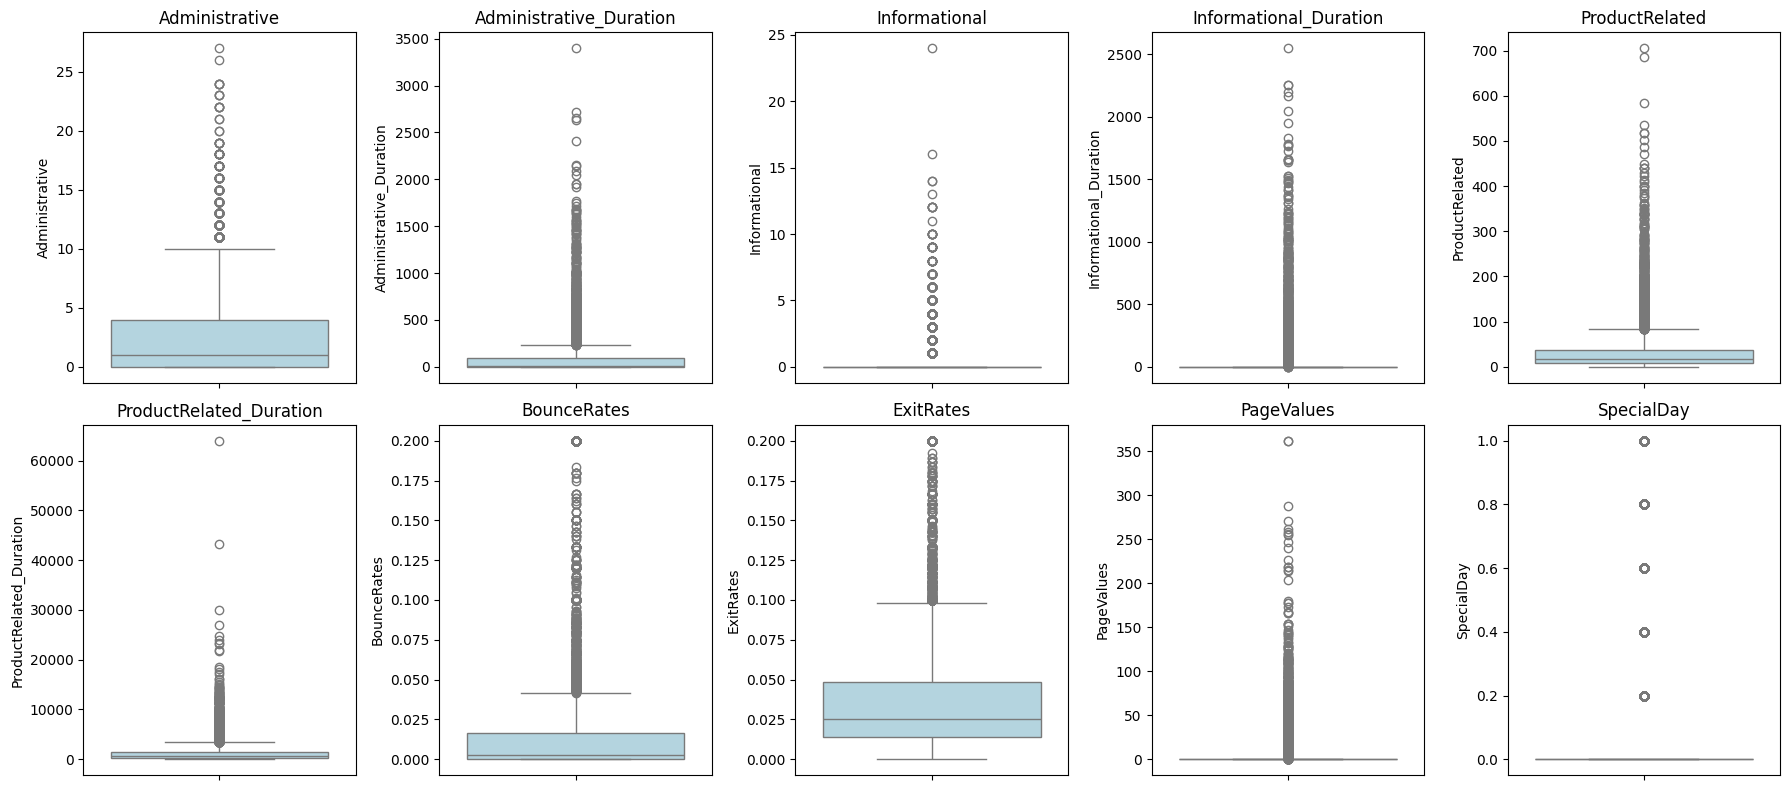

In [20]:
cat_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType',
            'Month', 'VisitorType', 'Weekend']
num_cols = [c for c in df.select_dtypes('number').columns if c not in cat_cols]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[col], ax=ax, color='lightblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

На диаграммах размаха видно, что все числовые признаки имеют сильно асимметричное распределение с длинным хвостом в сторону больших значений. Основная масса наблюдений сосредоточена около нуля, медиана находится в нижней части ящика, а выбросы расположены только в области больших значений. Это подтверждается и статистиками: у всех признаков среднее значительно больше медианы.

##Распределение числовых признаков


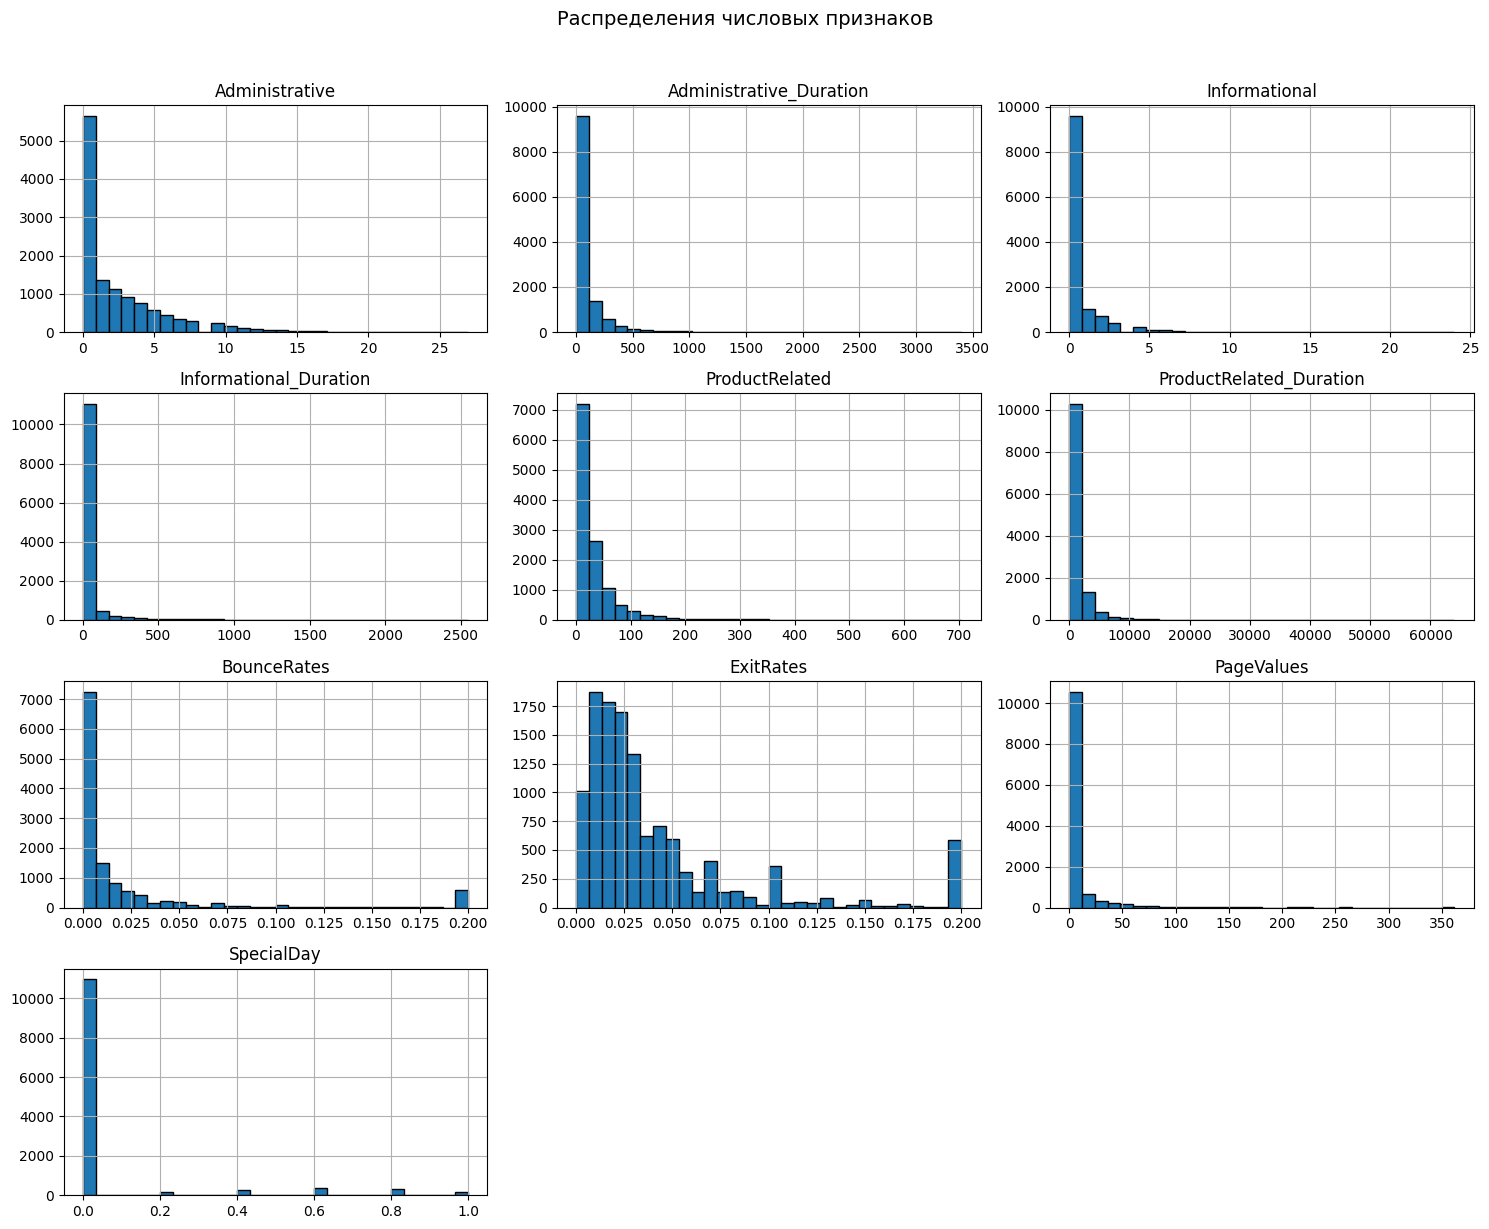

In [21]:
#разделим колонки на числовые и категориальные признаки
cat_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType',
            'Month', 'VisitorType', 'Weekend']
num_cols = [c for c in df.select_dtypes('number').columns if c not in cat_cols]

df[num_cols].hist(figsize=(15, 12), bins=30, edgecolor='black')
plt.suptitle('Распределения числовых признаков', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

##Категориальные признаки

In [22]:
cat_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType',
            'Month', 'VisitorType', 'Weekend']
df[cat_cols] = df[cat_cols].astype('category')

df[cat_cols].describe()          # count, unique, top, freq

,OperatingSystems,Browser,Region,TrafficType,Month,VisitorType,Weekend
count,12205,12205,12205,12205,12205,12205,12205
unique,8,13,9,20,10,3,2
top,2,2,1,2,May,Returning_Visitor,False
freq,6541,7883,4714,3911,3329,10431,9346


In [23]:
for col in cat_cols:
    print(col, df[col].nunique())
    print(df[col].value_counts(normalize=True).round(3).head(10), '\n')

OperatingSystems 8
OperatingSystems
2    0.536
1    0.209
3    0.207
4    0.039
8    0.006
6    0.002
7    0.001
5    0.000
Name: proportion, dtype: float64 

Browser 13
Browser
2     0.646
1     0.199
4     0.060
5     0.038
6     0.014
10    0.013
8     0.011
3     0.009
13    0.005
7     0.004
Name: proportion, dtype: float64 

Region 9
Region
1    0.386
3    0.195
4    0.096
2    0.092
6    0.066
7    0.062
9    0.041
8    0.035
5    0.026
Name: proportion, dtype: float64 

TrafficType 20
TrafficType
2     0.320
1     0.196
3     0.165
4     0.087
13    0.060
10    0.037
6     0.036
8     0.028
5     0.021
11    0.020
Name: proportion, dtype: float64 

Month 10
Month
May     0.273
Nov     0.244
Mar     0.152
Dec     0.140
Oct     0.045
Sep     0.037
Aug     0.035
Jul     0.035
June    0.023
Feb     0.015
Name: proportion, dtype: float64 

VisitorType 3
VisitorType
Returning_Visitor    0.855
New_Visitor          0.139
Other                0.007
Name: proportion, dtype: float64 

Wee

Сильный дисбаланс во всех признаках.

Browser: код 2 — 64.6%.

OperatingSystems: код 2 — 53.6%.

VisitorType: Returning_Visitor — 85.5%.

Month: May (27.3%) + Nov (24.4%) — 51.7%.

Редкие категории скорее всего объединим в одну Other.

##Корреляция.

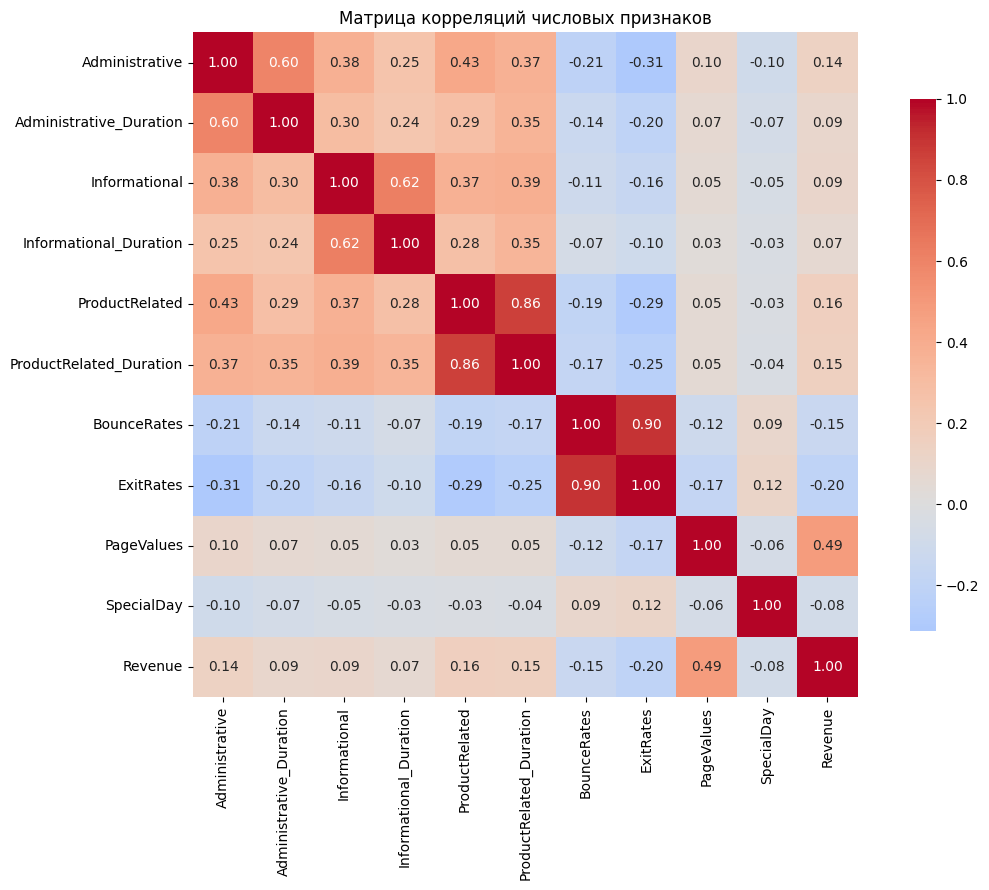

In [24]:
plt.figure(figsize=(12, 9))
corr = df[num_cols + ['Revenue']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Матрица корреляций числовых признаков')
plt.tight_layout()
plt.show()

Самая сильная связь с покупкой у признака PageValues (0.49), а признаки ExitRates и BounceRates наоборот мешают покупке (отрицательная связь). Также видно, что некоторые признаки дублируют друг друга: BounceRates и ExitRates связаны на 0.90, а ProductRelated и ProductRelated_Duration — на 0.86.

Сравним корреляции Пирсона и Спирмена

In [26]:
comparison = pd.DataFrame({
    'Pearson': df[num_cols + ['Revenue']].corr(method='pearson')['Revenue'].drop('Revenue'),
    'Spearman': df[num_cols + ['Revenue']].corr(method='spearman')['Revenue'].drop('Revenue')
})
comparison['Разница'] = (comparison['Pearson'] - comparison['Spearman']).abs()
print(comparison.sort_values('Разница', ascending=False).round(3))

                         Pearson  Spearman  Разница
PageValues                 0.492     0.626    0.134
Administrative_Duration    0.092     0.161    0.069
ProductRelated_Duration    0.150     0.213    0.063
ExitRates                 -0.204    -0.251    0.047
Informational_Duration     0.069     0.110    0.041
ProductRelated             0.156     0.194    0.038
Administrative             0.136     0.164    0.028
Informational              0.094     0.112    0.018
SpecialDay                -0.084    -0.088    0.005
BounceRates               -0.145    -0.144    0.001


Сравнение Пирсона и Спирмена подтверждает нелинейность связи PageValues с таргетом (разрыв 0.13 — самый большой). Также видно, что для *_Duration Спирмен надёжнее из-за выбросов. Это аргумент в пользу того, что деревья (RandomForest, GradientBoosting), скорее всего, покажут лучший результат, чем линейная логистическая регрессия.

##Связь признака с таргетом

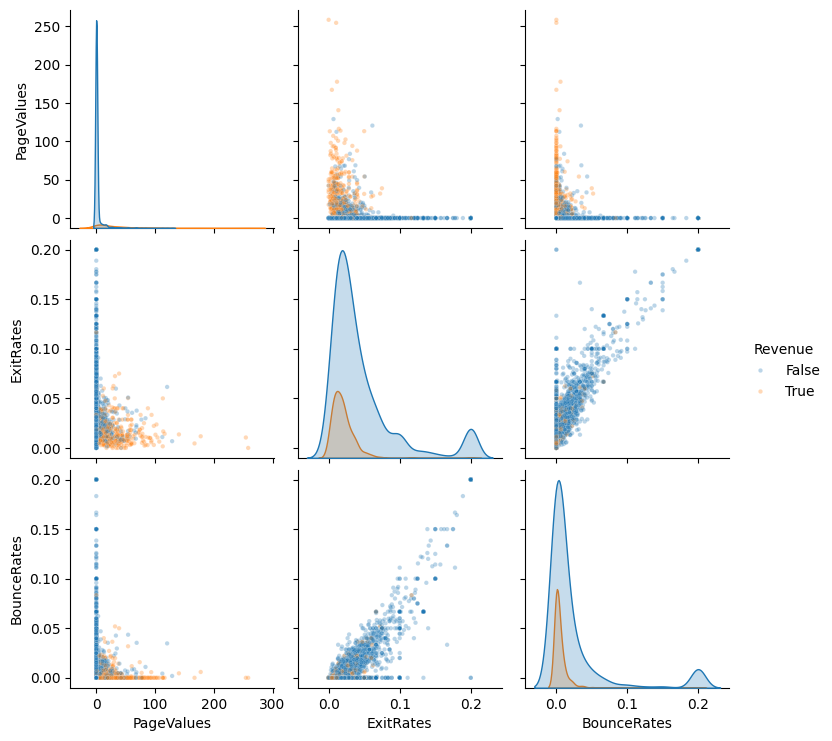

In [36]:
cols = ['PageValues', 'ExitRates', 'BounceRates', 'Revenue']
sns.pairplot(df[cols].sample(3000, random_state=42), hue='Revenue', plot_kws={'alpha': 0.3, 's': 10})

plt.show()

Видно что связь с таргетом нелинейная. Скорее всего  нелинейные модели покажут гораздо лучший результат, чем линейная регрессия.

In [38]:
mean_table = df.groupby('Revenue')[num_cols].mean().T.round(2)
median_table = df.groupby('Revenue')[num_cols].median().T.round(2)

comparison = pd.concat([mean_table, median_table], axis=1,
                        keys=['Среднее', 'Медиана'])
print(comparison)

                         Среднее          Медиана         
Revenue                    False    True    False    True 
Administrative              2.14     3.39    1.00     2.00
Administrative_Duration    74.64   119.48    0.00    52.37
Informational               0.46     0.79    0.00     0.00
Informational_Duration     30.60    57.61    0.00     0.00
ProductRelated             29.05    48.21   16.00    29.00
ProductRelated_Duration  1082.98  1876.21  526.00  1109.91
BounceRates                 0.02     0.01    0.00     0.00
ExitRates                   0.05     0.02    0.03     0.02
PageValues                  2.00    27.26    0.00    16.76
SpecialDay                  0.07     0.02    0.00     0.00


по медианам видно, что типичный покупатель — это клиент, у которого PageValues выше нуля, ProductRelated_Duration почти в 2 раза больше, а ExitRates ниже. Совпадает с тем, что показал pairplot.

## Общий вывод

**Данные.** В датасете 12330 сессий и 18 признаков, пропусков нет. Найдено 125 лишних дубликатов, среди них нет ни одной покупки, поэтому мы их удалили. Нулевые значения содержательные (пользователь не заходил в раздел), поэтому мы не считаем их пропусками. Ошибок в данных нет: отрицательных значений нет, доли лежат в [0, 1], коды в допустимых диапазонах. Единственная аномалия: у части сессий страниц больше нуля, а время равно нулю (135, 226 и 592 сессии для Administrative, Informational и ProductRelated).

**Целевая переменная.** Покупкой заканчивается только 15,63% сессий, то есть классы несбалансированы.

**Признаки.** Все числовые признаки сильно скошены, с длинным хвостом больших значений. Категориальные признаки тоже несбалансированы: например, в Browser на код 2 приходится 64,6%, в VisitorType на Returning_Visitor 85,5%, а в Month майские и ноябрьские сессии составляют 51,7%.

**Связь с покупкой.** Сильнее всего с покупкой связан PageValues (корреляция 0.49). BounceRates и ExitRates связаны с покупкой отрицательно. Часть признаков дублирует друг друга: BounceRates и ExitRates (0.90), ProductRelated и ProductRelated_Duration (0.86). Связь PageValues с таргетом нелинейная, поэтому, скорее всего, деревья (RandomForest, GradientBoosting) покажут лучший результат, чем логистическая регрессия.

**План дальше.**
- объединить редкие категории в Other;
- убрать или объединить сильно коррелирующие признаки;
- учесть дисбаланс классов (стратификация, class_weight, метрики F1 и ROC-AUC вместо accuracy);
- обучить логистическую регрессию как baseline и сравнить с RandomForest и GradientBoosting;
- проверить, как сессии с нулевым временем влияют на метрики.